# 12-LVGL图形界面开发

> 把显示、触摸、时间和资源组织成可维护的界面：LVGL负责对象和渲染逻辑，板级驱动负责把结果可靠地送到真实硬件。

这是「嵌入式单片机一套通关」十二篇笔记的第12篇，承接第11篇的ST7789、OLED、CST816T、DMA与坐标合同，把它们接到LVGL 8.x的显示和输入端口。本篇关注配置、tick、任务、flush、输入、对象、样式、资源、性能和验收。

本篇为中文Markdown笔记，含自绘示意图、接口合同、代码片段、独立算法检查和实验清单。未进行LVGL SDK编译、烧录、上板运行或电气测量；board_*、lcd_*、touch_*、app_*示例接口为需要工程实现的应用合同；lv_*为LVGL API，按锁定版本与配置使用。


## 1. 本篇范围、课程资料与版本边界

|资料|本篇使用方式|
|---|---|
|LVGL兼容手表屏|课程LVGL 8.3/8.4移植线索、显示与触摸衔接|
|第11篇屏幕显示与触摸驱动|ST7789窗口、RGB565、DMA、CST816T坐标合同|
|第10篇存储器与文件系统|图片/字体资源、FatFS与Flash/SD边界|
|LVGL结合FatFS、SquareLine UI结合单片机运行|文件资源、代码导出和中文字体|
|LVGL 8.4文档与8.3.11源码|显示、输入、tick、对象、资源和并发对照|

本篇以LVGL 8.x为主，示例接近8.3/8.4；不把LVGL 9的显示注册结构、颜色类型和刷新回调接口混入同一段代码。课程长代码和完整工程没有全部下载、编译或烧录。

目标硬件按前篇的240×280 ST7789+CST816T条件模型理解。控制器、面板偏移、DMA可达性、触摸INT行为和最高时钟要按手册及实物验证。LVGL能生成逻辑绘图请求，不会修复CS/DC、RGB565字节顺序、I²C上拉或坐标旋转错误。


## 2. LVGL处在什么位置

LVGL不是LCD控制器驱动，也不是触摸芯片驱动。它维护对象树、样式、布局、事件和脏区域；底层端口把需要刷新的区域转换成ST7789事务，把输入设备读数转换成LVGL可理解的点和按压状态。

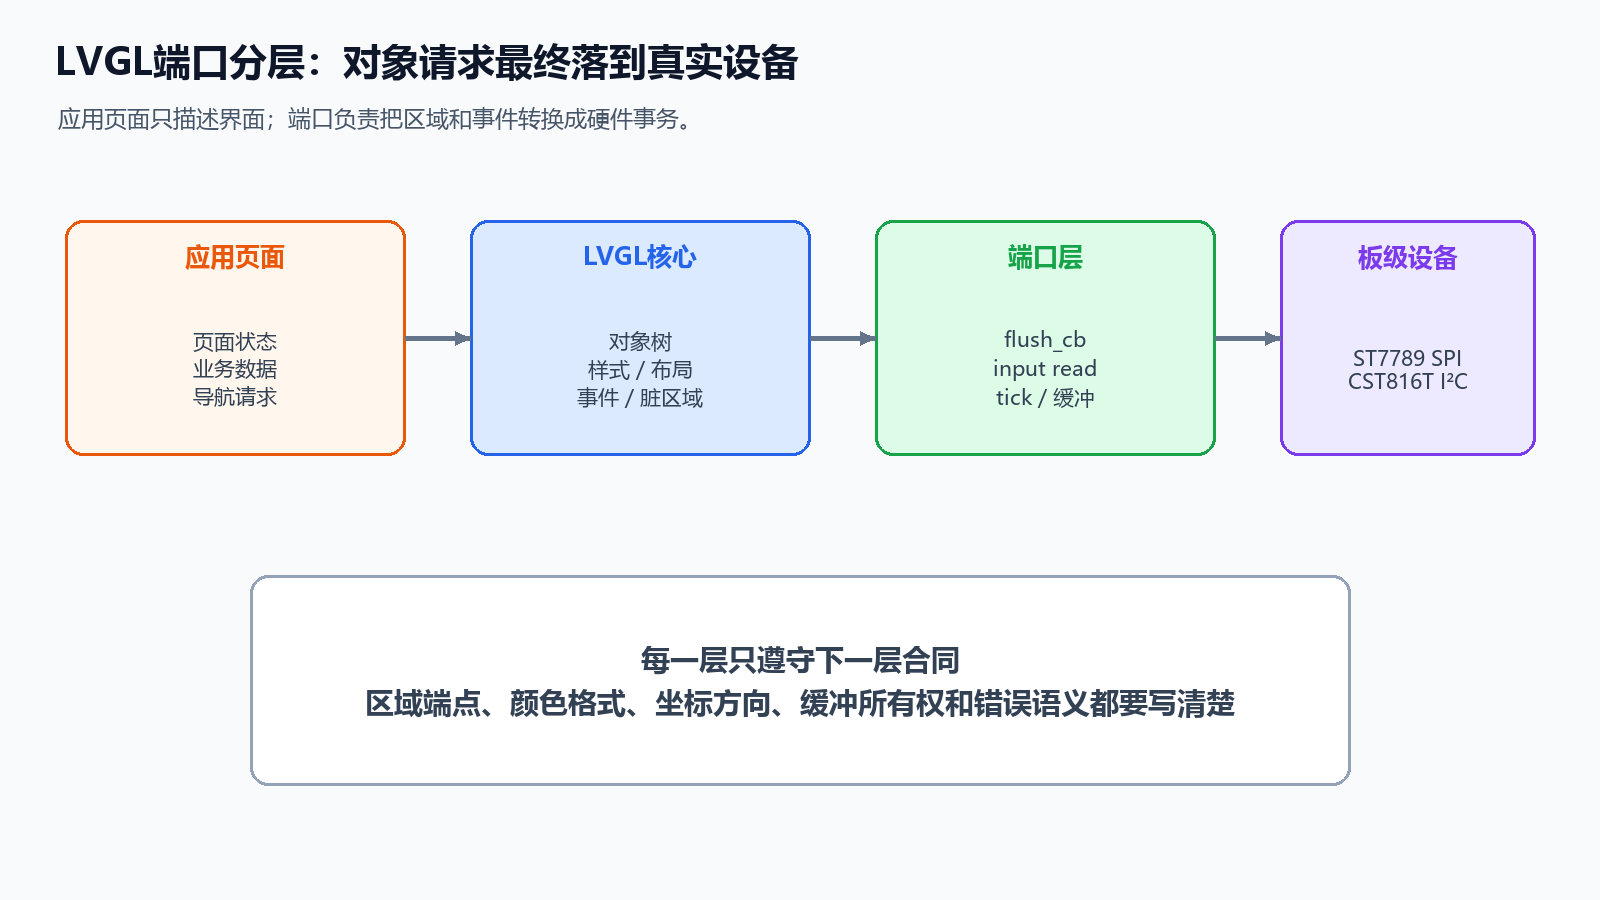

|层|负责|不应越权|
|---|---|---|
|应用页面|页面状态、业务数据、控件关系|不直接改SPI/GPIO|
|LVGL对象/样式|绘制、布局、事件、动画|不猜测屏幕针脚|
|LVGL端口|display/input/tick回调、缓冲所有权|不夹带业务动作|
|板级驱动|SPI/I²C、DMA、ST7789/CST816T|不创建按钮和页面|
|硬件|面板扫描、触摸采样、总线电气|不保证软件坐标语义|

显示有背光只证明一小部分硬件路径通电；LVGL页面能创建也不证明像素发到了面板。调试先分离裸显示、裸触摸，再接LVGL端口，最后接页面业务。


## 3. 对象树与生命周期

LVGL的基础对象是lv_obj_t。屏幕对象是对象树的根，按钮、标签、图片和容器是子对象。对象的坐标、尺寸、样式、事件和布局参数属于对象层。

对象生命周期要有明确所有者：页面创建函数创建对象和回调；页面切换函数保存当前屏幕指针；外设任务只更新快照或投递消息；删除对象后不再访问旧指针；静态字体、图片描述符和主题对象的生命周期覆盖使用期。

```c
typedef struct {
    lv_obj_t *screen;
    lv_obj_t *value_label;
    lv_obj_t *status_label;
} app_dashboard_t;

bool app_dashboard_create(app_dashboard_t *ui);
void app_dashboard_destroy(app_dashboard_t *ui);
```

上面是应用合同，不是LVGL自带API。destroy成功后清零指针；若页面采用缓存复用，就另写状态重置规则，不能既删除又继续使用旧对象。


## 4. 工程组织与版本集中点

建议把第三方库、端口和应用分开：

```text
Middlewares/lvgl/                 LVGL源码与配置
Port/lvgl_display_port.c/.h       draw buffer、flush_cb、DMA完成
Port/lvgl_input_port.c/.h         CST816T读取、坐标、pressed状态
Port/lvgl_tick_port.c/.h          单调时基
Hardware/ST7789、CST816T、OLED     控制器和总线驱动
App/ui_pages.c/.h                 页面、样式、事件
Board/bus、gpio、dma、rtos         板级接口和并发原语
```

LVGL升级时只替换库目录和经过审查的lv_conf.h，端口层集中处理版本差异。工程要确认C文件已加入编译分组、include路径正确、配置头可见、启用的字体和小部件真的参与构建。

只在工程树中看到文件，不代表文件已参与编译。建议构建日志输出LVGL版本、配置摘要和链接map，方便定位“代码没有被编译”与“运行时内存不足”的区别。


## 5. lv_conf.h是资源合同

配置会影响颜色、对象大小、内存、日志、断言、动画、文件系统和可用小部件。常见检查如下：

|配置方向|要回答的问题|
|---|---|
|LV_COLOR_DEPTH|是否与ST7789线上RGB565一致|
|默认字体|字体是否在Flash中，中文字符是否包含|
|内存分配|LVGL堆来自哪里，峰值和失败如何记录|
|日志/断言|调试与发布构建保留哪些诊断|
|小部件|页面是否使用，启用后增加多少Flash/RAM|
|文件系统|驱动字母和打开/读取/关闭合同是什么|

LV_COLOR_DEPTH=16不自动解决线上字节序；颜色深度、主机内存布局、线上顺序和DMA宽度分别核对。同一个配置文件被多个工程共享时，任何改动都可能改变另一个工程的对象布局。

LV_COLOR_16_SWAP是LVGL颜色/图片数据布局选项，不是ST7789的MADCTL，也不是SPI的MSB-first设置。课程SquareLine截图中的“16 bit swap”必须和图片转换器、`lv_color_t`缓冲以及flush发送方式一起验证；只改其中一处，红蓝或整体彩色都可能异常。

把配置当成版本化输入，而不是复制一个“能编译”的模板。换颜色深度或默认字体后，图片和字体资源也可能需要重新生成。


## 6. 初始化顺序：底层时序就绪，再注册端口

最小顺序为：供电与总线时序就绪 → 裸LCD/触摸初始化 → `lv_init()` → 注册display与input → 创建页面 → 周期执行handler。显示和输入就绪后再创建对象，可避免首轮刷新进入未初始化设备。

```c
/* 以下app/board/lcd/port函数由工程实现；不是LVGL现成API */
bool app_gui_init(void)
{
    if (!board_bus_init()) return false;
    if (!lcd_init()) return false;
    lv_init();
    if (!app_display_register()) return false;
    if (!app_input_register()) return false;
    if (!app_pages_init()) return false;
    return true;
}
```

裸机中的GPIO/SPI可以先于lv_init准备；关键是调用任何LVGL对象/注册API前完成lv_init。如果启用FatFS内置适配器，8.3.11的lv_init会通过extra初始化文件系统胶水，胶水里的自定义初始化也必须符合此顺序。

**接FreeRTOS后要检查延时的依赖。** 课程将驱动毫秒延时替换为vTaskDelay，并强调在启动任务中初始化。正确原因是驱动此时依赖已经运行的调度器和tick；并非每个独立裸机驱动都必须等待RTOS。使用任务延时的lcd/touch/fs初始化放进scheduler启动后的任务，任务睡眠用正确毫秒换算，微秒总线时序另实现。

`vTaskStartScheduler()`正常启动后不继续按普通主循环执行其后的初始化；若它返回，处理调度器启动失败。GUI初始化只做一次，避免重复创建驱动、文件系统适配器和页面。

记录各阶段结果：BUS_READY、LCD_READY、LVGL_READY、DISPLAY_REGISTERED、INPUT_REGISTERED、PAGE_READY。触摸或SD卡失效可进入明示降级界面；显示驱动注册失败则不能继续向空显示对象创建页面。


## 7. 显示回调与区域端点

LVGL 8的显示回调接收lv_area_t。常见8.x合同中x2、y2是包含末点的坐标；第11篇应用层用半开区间，所以要加一：

```c
bool app_area_to_halfopen(const lv_area_t *a, app_rect_t *r,
                          int32_t width, int32_t height)
{
    if (a == NULL || r == NULL || width <= 0 || height <= 0)
        return false;
    int64_t x1 = (int64_t)a->x2 + 1;
    int64_t y1 = (int64_t)a->y2 + 1;
    if (a->x1 < 0 || a->y1 < 0 || x1 > width || y1 > height)
        return false;
    if (a->x1 >= x1 || a->y1 >= y1) return false;
    r->x0 = a->x1; r->y0 = a->y1;
    r->x1 = (int32_t)x1; r->y1 = (int32_t)y1;
    return true;
}
```

不要把x2、y2直接当半开终点，否则每个刷新区域会少一列和一行。不同8.x小版本的结构声明可能有差异，以工程头文件为准。

flush_cb负责提交区域和像素数据，并在底层完成后调用lv_disp_flush_ready。同步发送可在发送返回后调用；DMA必须等DMA和SPI最后一位都完成。

LVGL保存显示驱动和绘图缓冲的指针，驱动描述符、缓冲描述符及其数组不能是初始化函数结束后就失效的局部对象。部分双缓冲模式下，LVGL会等待前一次flush归还；端口应保持“只允许合同规定数量的事务在途”，不能自行再排队而丢失完成顺序。

**完整注册的8.3.11形式**

```c
static lv_disp_drv_t display_drv;
static lv_disp_t *display;
static lv_disp_draw_buf_t draw_buf; /* 缓冲在第8节初始化 */
static void app_flush(lv_disp_drv_t *drv, const lv_area_t *area,
                      lv_color_t *color_p); /* 项目实现 */

bool app_display_register(void)
{
    app_draw_buf_init();
    lv_disp_drv_init(&display_drv);
    display_drv.draw_buf = &draw_buf;
    display_drv.hor_res = 240;
    display_drv.ver_res = 280;
    display_drv.flush_cb = app_flush;
    /* 本篇基线：partial缓冲、LVGL不旋转、不额外加offset */
    display_drv.full_refresh = 0;
    display_drv.direct_mode = 0;
    display_drv.rotated = LV_DISP_ROT_NONE;
    display_drv.sw_rotate = 0;
    display = lv_disp_drv_register(&display_drv);
    return display != NULL;
}
```

这是一个注册片段，依赖draw buffer和flush的完整实现。`draw_buf`、`display_drv`及像素数组保持静态生存期；前文/第8节重复名称用于说明同一对象，整合时只定义一次。

本篇默认LVGL offset_x/y为0，panel RAM偏移由ST7789驱动加一次。已读8.3.11源码会在调用flush前加上LVGL自己的offset；若配置了它，回调收到的坐标已有偏移，不能再用“未偏移逻辑area”检查方式，也不能在LCD层重复加同一偏移。

**像素数据与area对应。** partial基线下，区域(10,20)～(29,34)含20×15=300个像素，紧密16bit流为600B；有效坐标无需再次剪裁。若自定义回调还要裁剪，源buffer的起点和每行stride必须一起调整，否则显示位置正确、图像内容错行。


## 8. 绘图缓冲：整帧、条带与双缓冲

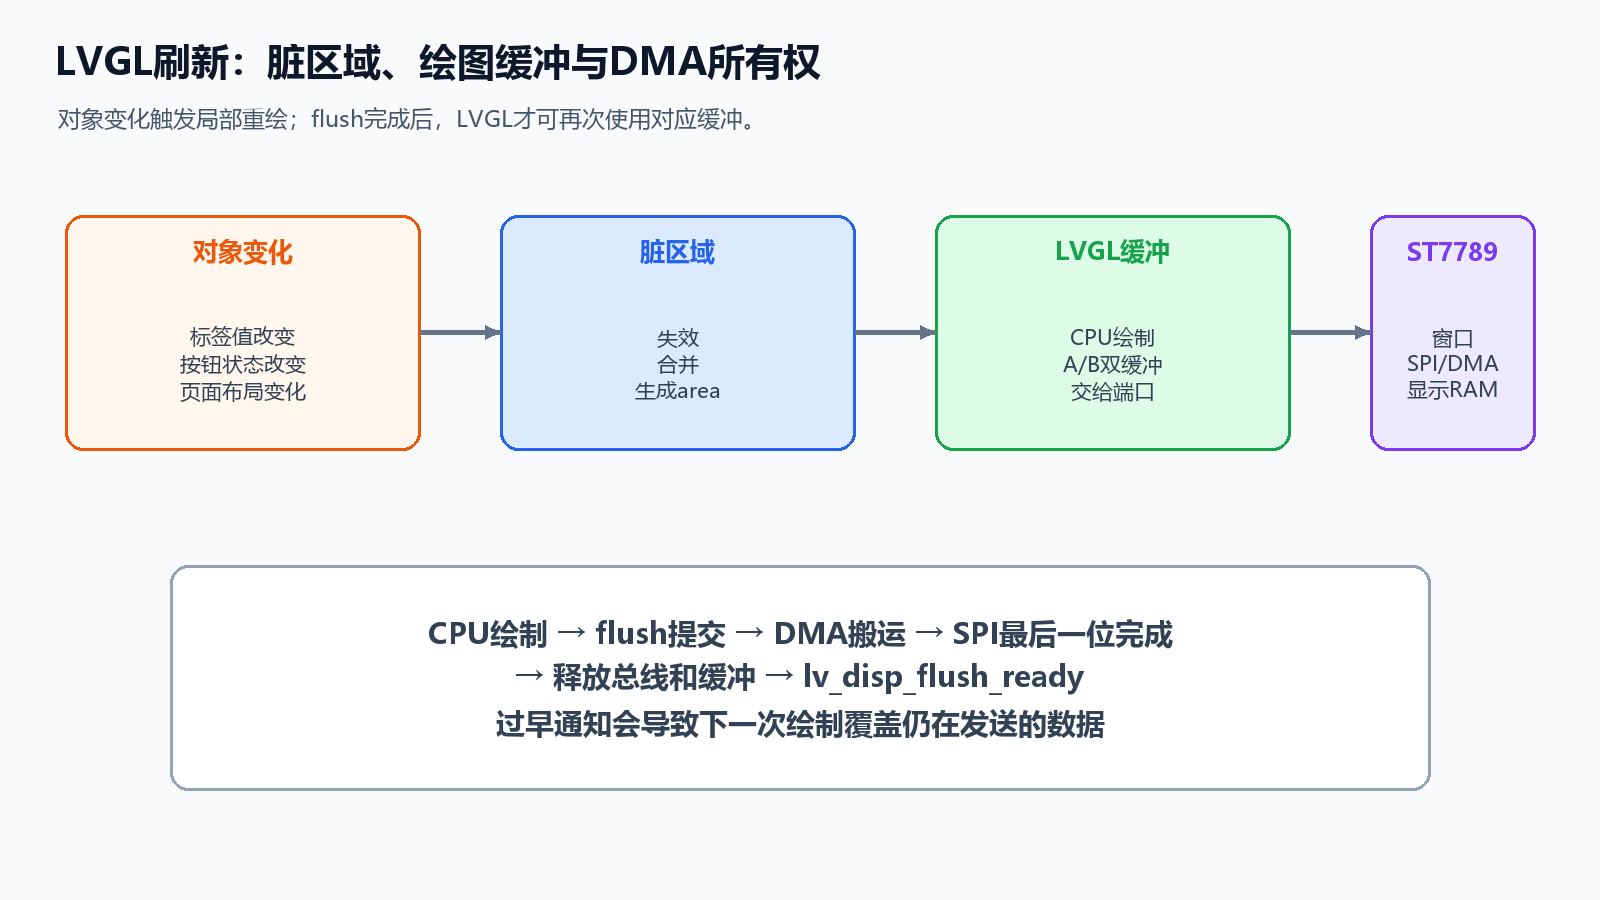

240×280 RGB565整帧约134400B，双整帧约268800B；240×20双条带约19200B。条带更适合RAM有限的单片机，但会增加事务次数和调度边界。

```c
static lv_color_t draw_a[240 * 20];
static lv_color_t draw_b[240 * 20];
static lv_disp_draw_buf_t draw_buf;

void app_draw_buf_init(void)
{
    lv_disp_draw_buf_init(&draw_buf, draw_a, draw_b,
                          240u * 20u);
}
```

数组大小是教学算例。lv_color_t大小受LV_COLOR_DEPTH和配置影响，不能假定所有工程都是2字节；用sizeof和实际配置核对。

双缓冲允许一块被DMA发送、另一块由LVGL绘制，前提是端口正确等待和报告完成。缓冲数量不是自动的并发协议，所有权仍要由端口维护。

`lv_disp_draw_buf_init`的第四个参数单位是**像素元素数**，不是字节。240×20为4800个元素；在16bit配置下对应9600B，传入9600会让库以为缓冲比实际大一倍。初始化函数不能把栈上数组地址注册给LVGL。

| 模式 | 缓冲要求 | SPI手表屏选择 |
|---|---|---|
| partial单缓冲 | 可小于整屏 | 同步基线最容易调试 |
| partial双缓冲 | 两块小区域缓冲 | DMA与CPU可交叠 |
| full_refresh | 每次重绘整屏 | 带宽不足时不要默认启用 |
| direct_mode | 要求整屏缓冲 | 不能套紧密area流的flush假设 |

官方8.4建议从约屏幕1/10大小缓冲开始评估，本屏为6720像素，240×28为13440B；240×20是本篇节省RAM的试算，不宣称它对所有界面性能最优。条带行数也不是每个flush一定发送的行数，窄矩形可能装入更多行。

RGB扫描控制器可以在整帧双缓冲间换显示地址；SPI ST7789需要把像素写入独立控制器RAM，不能仅换一个MCU指针就更新屏幕。


## 9. flush完成：独立进展路径与有界恢复

一次flush持有的资源包括：回调的drv指针、像素buffer借用权、ST7789窗口、CS/DC状态和SPI总线访问权。**成功完成**后解除借用，再调用`lv_disp_flush_ready(drv)`；每次提交只归还一次，延迟或重复通知都属于端口错误。

```text
IDLE → VALIDATE → SET_WINDOW → TRANSFER → FINISH → READY
                                  ↓error/timeout
                     STOP_DMA_SPI → CONFIRM_NO_BORROW
                                  → MARK_DISPLAY_LOST → READY
```

DMA完成说明源内存不再被DMA读取；SPI最后一位完成后才能改变DC/CS。本篇采用更保守的合并完成合同：两项都满足再归还LVGL buffer。失败不是“像素已经成功显示”，但确认停止借用后仍须解开LVGL的flushing等待，再安排重初始化和必要的全屏重绘。

**不要把完成工作只排到GUI主循环下一轮。** 已读8.3.11刷新源码在单缓冲或提交第二块partial双缓冲时可能在handler内部等待`draw_buf->flushing`归零。若GUI线程持着LVGL锁等待，而完成路径还在等它退出handler处理消息，系统会死锁。

可选实现：

| 完成路径 | 进展条件 | 注意事项 |
|---|---|---|
| 同步flush | 回调内有界等SPI完成 | 最小基线，CPU等待多 |
| ISR完成通知 | ISR确认端口完成后flush_ready | 不创建对象；中断内等待须短且有界 |
| 独立传输服务任务 | 无需GUI锁也能完成归还 | RTOS优先级不能被GUI忙等长期压住 |
| `wait_cb` | handler等待时服务已完成事务 | 不重入handler或对象API；含超时恢复 |

8.4线程文档明确`lv_tick_inc`和`lv_disp_flush_ready`是可在中断使用的例外；其它对象函数仍放GUI线程。即使采用服务任务，也不要让它先获取GUI锁才归还本来被GUI锁保护的等待事务。

如果SPI总线用RTOS mutex，获取与释放遵守“同一任务持有者”合同，ISR不能当作owner释放mutex。可在wait_cb中唤醒/等待原持有任务完成收尾，或由专用总线服务任务拥有整次事务，ISR仅发布状态。不要让ISR调用普通任务API。

传输序号用于拒绝过期完成：事务12超时已取消后，迟到的DMA12中断不能归还事务13的buffer。故障处理先停DMA/SPI、确认不再读内存、收回CS/锁，再结束等待；记录失败区域，显示任务在安全点重建控制器和失效画面。

`lv_disp_flush_is_last`表示当前渲染批次的最后一块，不代表SPI已经结束，也不代表面板已扫描显示。它可用于统计一次渲染批次，不能代替硬件完成位。


## 10. RGB565、swap、stride与DMA缓存

LVGL颜色值、缓冲内存布局和ST7789线上格式分开定义。本篇基线为`LV_COLOR_DEPTH=16`、`LV_COLOR_16_SWAP=0`，生成显式高字节先发的RGB565流；这是一个可检查方案，而非唯一方案。

```c
#if LV_COLOR_DEPTH != 16 || LV_COLOR_16_SWAP != 0
#error "This converter requires RGB565 with LV_COLOR_16_SWAP=0"
#endif

bool app_rgb565_be(const lv_color_t *src, size_t pixels,
                   uint8_t *dst, size_t capacity)
{
    if (src == NULL || dst == NULL || pixels > capacity / 2u)
        return false;
    /* src/dst不重叠，调用者提供完整紧密源区域 */
    for (size_t i = 0; i < pixels; ++i) {
        uint16_t c = src[i].full;
        dst[2u*i] = (uint8_t)(c >> 8);
        dst[2u*i + 1u] = (uint8_t)c;
    }
    return true;
}
```

仅16bit无swap时把full当标准RGB565数值。已读8.3.11颜色源码在swap=1时改变16bit通道布局；此时直接取full再高字节先发，会再交换一次。例如红色无swap时数值F800、小端内存00 F8；swap配置下同一红色内存可直接成为F8 00。**选择一条转换路径并让资源匹配，别叠加swap。**

| 路径 | LVGL配置/资源 | SPI发送合同 |
|---|---|---|
| 显式转换 | 16bit、swap=0 | 条带转换为BE字节再发 |
| 直接8bit DMA | 匹配16bit swap布局 | 经验证后直接发内存字节 |
| 16bit SPI帧 | 数据元素与外设宽度配套 | 按寄存器装载/帧比特顺序核对 |

额外BE条带会增加RAM。不能把函数内局部转换数组交给异步DMA后返回；转成持久端口缓冲，等完成后复用。若只是传输层分多块，不得提前通知整次LVGL flush完成。

partial区域通常紧密排列；direct_mode整帧中一小块仍有整屏stride，不能把区域宽度乘高度直接连续读。BMP行对齐、PNG/JPEG解码和LVGL图像数据又是不同格式。

带Data Cache的MCU按实际芯片、方向和内存区做clean/invalidate、对齐；GD32目标是否存在相关cache另核实。颜色、内存可达性、DMA宽度和cache旧数据分别排错，先用已知红F800、绿07E0、蓝001F、白FFFF确认。


## 11. 触摸read_cb、事件缓存与故障取消

输入端口消费第11篇已经验证、校准后的样本，不在每个read_cb里无限等I²C。样本含坐标、finger0/1、时间/序列和有效性；I²C失败代表未知，不能直接伪造正常UP。

```c
typedef struct {
    int16_t x, y;            /* 本篇基线：已旋转的逻辑坐标 */
    bool pressed;
    bool valid;
    uint32_t age_ms;
} app_touch_state_t;

/* 项目提供线程安全快照；false表示无有效样本 */
bool touch_port_get(app_touch_state_t *state);
```

正常路径才把最新有效状态写入`lv_indev_data_t`：finger1为`LV_INDEV_STATE_PRESSED`，有效finger0为`LV_INDEV_STATE_RELEASED`；UP保留最后有效点。注册用`lv_indev_drv_init`、`LV_INDEV_TYPE_POINTER`、`read_cb`和`lv_indev_drv_register`，保存返回的`lv_indev_t *`供取消处理。

**LVGL的read数据没有本篇应用CANCEL的第三种按压状态。** 给对象手动发送`LV_EVENT_CANCEL`也不自动清除LVGL输入捕获。要在GUI上下文做明示桥接，防止通信失效产生CLICKED。

基于已读8.3.11实现，可采用“失效后放弃当前手势，恢复前等待真实释放”的策略：

```text
新会话：有效DOWN → 保留坐标和会话 → LVGL正常处理
故障超预算：
    GUI侧标会话cancelled，禁止本会话业务提交
    lv_indev_wait_release(touch_indev)，抑制后续普通点击
    read_cb报告用于结束内部捕获的释放，清理按下视觉状态
    应用仍处于await_real_release，不接受恢复后的finger1为新点击
恢复且完整finger0：
    清await_real_release，新会话才可接受下一次DOWN
```

该内部释放用于取消而非正常点击；业务回调还要检查会话有效性。8.3.11的wait_until_release路径发送PRESS_LOST并清捕获，正常release路径则可能发送CLICKED。若选lv_indev_reset方案，需另清目标按下态及等待释放规则，不访问库内部proc字段。精确回调行为按锁定版本再做断线实验。

一次短暂读错是否立即取消、静止长按多久变stale，是项目策略，取决于触摸固件INT是否提供持续通知，不能套固定30ms。无有效历史点时以明确初始released开始，不能发布未初始化坐标。

快速DOWN→UP可能在两次LVGL轮询之间结束。端口可以缓存关键边沿，`data->continue_reading`表示还有数据；MOVE可合并，DOWN/UP不可静默丢。队列满时取消会话并统计，避免卡住pressed或制造重复点击。


## 12. 坐标旋转：手动方案与LVGL方案分开选

**本篇注册基线是LVGL不旋转。** `rotated=LV_DISP_ROT_NONE`、`sw_rotate=0`、offset_x/y=0；ST7789驱动负责面板方向/偏移，输入端口按第11篇把原始点变换到最终逻辑尺寸。此基线的数学映射为：

|视觉顺时针角度|逻辑尺寸|输入映射|
|---|---|---|
|0°|240×280|(rx,ry)|
|90°|280×240|(279-ry,rx)|
|180°|240×280|(239-rx,279-ry)|
|270°|280×240|(ry,239-rx)|

显示方向、窗口、缓冲宽度、页面布局和触摸变换成套管理。中心点不能识别镜像，四角编号、1px边框和触摸四角更可靠。控制器RAM offset只在显示驱动加，不自动给触摸坐标加同一数。

**如果采用LVGL的rotated/sw_rotate接口，输入坐标也会被LVGL变换。** 8.4文档和8.3.11输入源码均说明/实现此行为，read_cb按该版本规定提供基准坐标，不再手动旋转为最终点。`LV_DISP_ROT_90`定义与本篇数学“内容顺时针90°”不能仅凭编号视为相同；文档还涉及物理屏转动后的补偿方向。

软件旋转会额外转换像素并限制full_refresh/direct_mode组合；硬件旋转需要驱动协作。先选一套，测四角，再记录版本、原点、宽高、MADCTL、offset和旋转责任，不能让库、LCD和触摸各转一次。

校准乘法前就扩展到64位，避免先在int32中相减溢出：

```c
bool app_map_axis(int32_t raw, int32_t rmin, int32_t rmax,
                  int32_t count, int32_t *out)
{
    if (out == NULL || rmax <= rmin || count <= 0 ||
        raw < rmin || raw > rmax) return false;
    int64_t span = (int64_t)rmax - (int64_t)rmin;
    int64_t num = ((int64_t)raw - (int64_t)rmin) * (count - 1);
    *out = (int32_t)(num / span);
    return true;
}
```

count是像素数量，目标最大索引count-1。不要把理论12bit 4095强行作为感测最大值；像素化输出先范围检查。校准范围、容差、镜像和二维仿射参数另按实物验证。


## 13. tick：毫秒单位、RTOS换算与溢出

LVGL时间推进与handler调用是两条工作。`lv_tick_inc(x)`里的x是**已经经过的毫秒**，而非RTOS tick个数；handler处理到期任务和绘图，不能替代时间源。

**方案A：LV_TICK_CUSTOM=0**

```c
/* 只有硬件回调确实每1ms发生，才每次加1 */
void board_1ms_callback(void)
{
    lv_tick_inc(1u);
}
```

若真实节拍为10ms，每次应加10ms；周期非整数毫秒时使用经过时间或分数累积，不每次粗略四舍五入造成长期漂移。不得同时接硬件1ms和RTOS hook导致加倍。

**方案B：LV_TICK_CUSTOM=1**

```c
/* 工程提供header和函数；8.3.11配置方式 */
#define LV_TICK_CUSTOM 1
#define LV_TICK_CUSTOM_INCLUDE "board_gui_time.h"
#define LV_TICK_CUSTOM_SYS_TIME_EXPR (board_gui_ms32())
```

`board_gui_ms32`返回单调毫秒，再由LVGL读取；这时不再另喂tick_inc。若时间来源是微秒计数器，先使用64位或做32位溢出扩展，再除1000并截成uint32毫秒。直接把32位微秒除1000在约71.58分钟回零，会破坏期望的毫秒溢出间隔。

课程用xTaskGetTickCount直接作毫秒，只在配置1kHz且相应时基合同满足时成立。100Hz下tick=1实际10ms，直接使用会让动画时间慢10倍；一般换算使用64位中间量、正确处理计数器周期/溢出，或维护独立毫秒时钟。

延时也单独换算：vTaskDelay参数是tick，pdMS_TO_TICKS小于一个tick的毫秒可能得到0。需要让出CPU时保证至少一个tick；GUI最小响应粒度仍受RTOS频率限制。微秒I²C延时不能换成vTaskDelay。

uint32毫秒约49.71天回卷；正常时间差可用`(uint32_t)(now - then)`，在约定的短间隔内比较。计数器溢出、暂停恢复和定时器延迟应覆盖验收，不用墙上日期时间作为动画时基。


## 14. lv_timer_handler与GUI任务

定时器处理函数负责执行到期任务、动画、输入处理和必要重绘。主循环或GUI任务应周期性调用，不要无睡眠占满CPU。

```c
void gui_task(void *arg)
{
    (void)arg;
    for (;;) {
        uint32_t wait_ms = lv_timer_handler();
        if (wait_ms < 1u) wait_ms = 1u;
        if (wait_ms > 20u) wait_ms = 20u;
        rtos_delay_ms(wait_ms);
    }
}
```

返回类型和辅助函数以实际LVGL 8.x版本为准。触摸响应、动画流畅度、刷新区域、CPU占用和功耗共同决定周期，不能固定套一个万能值。

官方8.4示例常以约5ms处理一次来保持响应；这只是起点，SPI整屏事务、资源解码或低功耗策略可能需要更长周期或事件唤醒。测量handler最大耗时和下一次截止时间，再选任务延时。

DMA完成回调在ISR中发生时，不调用对象API；flush_ready按第9节的例外合同及时归还，页面更新另通知GUI任务。

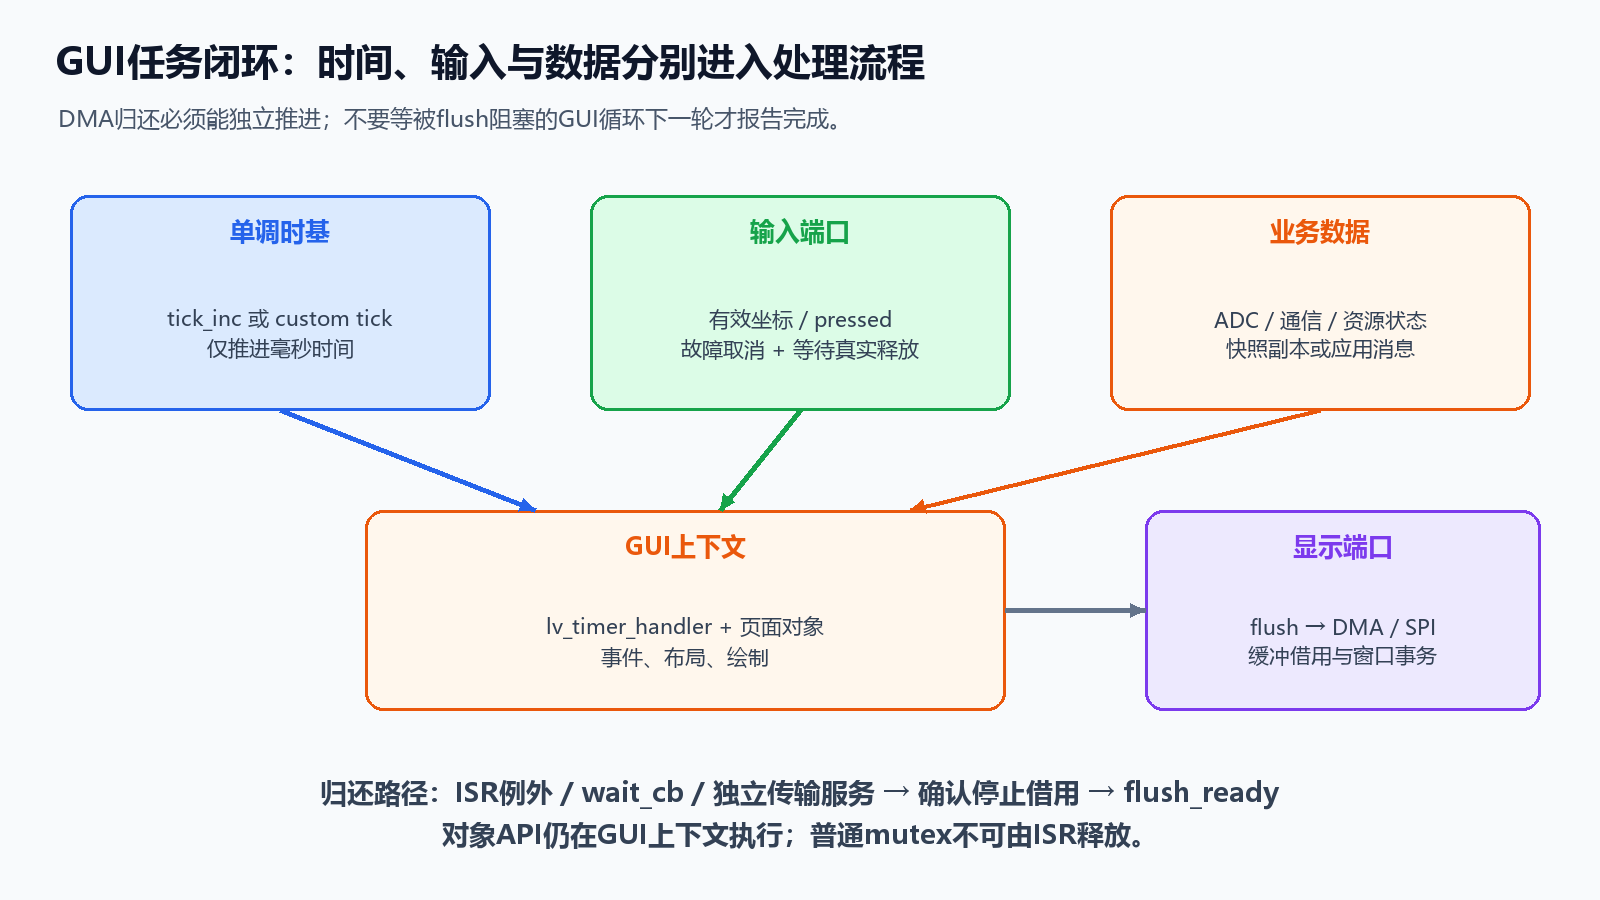

注意：上述循环只说明handler节拍，**DMA归还需要第9节的独立进展路径**，不能只靠循环下一轮处理完成队列。官方8.4列出tick_inc与flush_ready的ISR例外，ISR可以按端口约定归还buffer，其它对象操作仍由GUI任务处理。

`LV_DISP_DEF_REFR_PERIOD`和`LV_INDEV_DEF_READ_PERIOD`分别影响显示刷新和输入读取的库定时器，即使每5ms调用handler也不自动变为5ms全屏绘图。定义handler调用周期、定时器周期、实际flush耗时和面板扫描帧率四个指标，别把它们统称为fps。

用5ms开始验证只是官方示例起点；100Hz的RTOS最小1tick是10ms，实际handler周期不可能通过vTaskDelay达到1ms。资源读取、字体渲染和动画 callback也会增加handler耗时，记录最大值而非只看平均值。


## 15. 线程安全与单一GUI访问者

许多LVGL 8.x对象操作默认要求同一个GUI线程串行完成。全局互斥锁也不能让ISR安全调用对象API。

推荐单线程模型：传感器、触摸和通信任务只更新数据快照或投递消息，GUI任务读取消息并改对象。若采用显式LVGL锁，则写清锁范围、ISR限制、回调重入和flush完成规则。

```c
typedef struct {
    int32_t temperature;
    bool sensor_ok;
    uint32_t seq;
} app_snapshot_t;

bool app_post_snapshot(const app_snapshot_t *s);
```

不要把生产者会继续改写的结构体指针放进异步队列。复制快照、加序列号和检查队列深度，才能区分数据没来与页面没刷新。

事件和lv_timer回调本来运行在handler上下文中，采用单GUI线程时可直接调用对象API。若GUI任务已经持有非递归mutex，回调再获取同一锁会自锁；约定“进入handler前持锁，内部回调不重复获取”。

lv_async_call只安排下一次handler执行，不是一个可从任意任务/ISR安全调用的消息队列；调用它仍遵守LVGL访问规则，且它保存用户数据指针而不是副本。外部任务先投递应用队列，GUI线程再调用lv_async_call或对象函数。

规定锁顺序，例如GUI锁→资源服务请求；DMA归还绝不依赖GUI锁。优先级、总线锁、文件系统锁和对象生命周期一起审查，不能只在lv_label_set_text前随意加锁。


## 16. 事件语义：点击、长按、值改变和冒泡

一次按压可以产生多个事件，但业务动作只选择相应语义触发一次。

| LVGL 8.x事件 | 用途/边界 |
|---|---|
| PRESSED / PRESSING | 起始/持续按压，适合视觉与预览 |
| RELEASED | 释放路径，不应一概当确认 |
| SHORT_CLICKED | 短按后释放，无滚动 |
| CLICKED | 未滚动的释放，**长按后也可能触发** |
| LONG_PRESSED / LONG_PRESSED_REPEAT | 长按/重复动作 |
| PRESS_LOST | 滑出目标或取消捕获等情况 |
| VALUE_CHANGED | 控件的值变化，见具体控件合同 |

因此要区分“短按确认”和“长按进入设置”，短按业务用SHORT_CLICKED或显式会话判断，不能同时绑定CLICKED与LONG_PRESSED后假设互斥。

```c
static void app_confirm_cb(lv_event_t *e)
{
    if (lv_event_get_code(e) != LV_EVENT_CLICKED) return;
    if (!app_input_session_valid()) return; /* 本篇故障取消策略 */
    app_request_action(APP_ACTION_CONFIRM); /* 非阻塞业务队列 */
}
/* 只为本按钮注册一次；app函数由工程提供 */
void app_bind_confirm(lv_obj_t *button)
{
    lv_obj_add_event_cb(button, app_confirm_cb, LV_EVENT_CLICKED, NULL);
}
```

普通按钮的按下视觉状态由LVGL管理，不必在PRESSED回调再手动加PRESSED。如果事件绑定LV_EVENT_ALL，先判断code；避免重复初始化页面重复绑定同一回调，造成一次动作执行两遍。

事件冒泡时`lv_event_get_target`是原始触发对象，`lv_event_get_current_target`是当前执行回调的对象；应用上下文用user_data传入并保持生存期。已有8.4文档的冒泡段落仍有旧API文字，精确名字以8.3.11头文件和代码为准。

事件回调不阻塞Flash写入、网络或长SPI事务；只投递应用意图。对象删除、页面切换、输入故障都会影响捕获和状态，先取消旧会话，导航排到安全边界。绘制类DRAW事件不修改对象布局/属性，否则会在渲染期间再次失效。

LV_EVENT_CANCEL是库中特定过程的取消事件名，不等于触摸CANCEL的通用实现。第11节的输入桥接负责结束内部捕获，业务回调同时拒绝失效会话。


## 17. 页面、屏幕与导航

屏幕对象适合表示页面根节点，容器表示页面内部区域。导航请求由GUI任务处理，不从DMA ISR、I²C中断或底层驱动直接创建页面。

```c
typedef enum {
    APP_PAGE_HOME,
    APP_PAGE_SENSOR,
    APP_PAGE_SETTINGS
} app_page_id_t;

bool app_show_page(app_page_id_t id, bool animated);
```

缓存旧页面能减少创建开销，却增加RAM和状态复位复杂度；销毁重建节省常驻内存，却要重新绑定数据和样式。先选一种策略并记录。

页面退出要覆盖返回、超时、低功耗、异常和资源失败。失败页面显示可理解状态并保留重试或返回路径，不能让空指针进入绘图回调。

8.x屏幕根对象用`lv_obj_create(NULL)`，不是在lv_scr_act下再建一层“屏幕”。创建完成后用`lv_scr_load(screen)`或`lv_scr_load_anim(...)`加载。动画切换的auto_del策略、页面缓存和手动lv_obj_del不能同时抢着销毁同一屏幕。

删除父对象通常处理其子对象及相关库资源，但应用独立创建的lv_timer、异步请求和自己持有的buffer不自动遵循你的业务生命周期。退出页先取消这些引用，再删除并置空指针；给资源请求加页面generation，旧请求完成不能更新新页面。

屏幕之外的layer_top常驻于显示对象，适合弹窗/状态层。它不是当前screen的普通子树，切页时不一定随旧screen删除，故障提示与导航需明确何时关闭。


## 18. 样式、状态与主题



样式描述颜色、字体、边框、圆角、内边距和阴影；对象状态描述默认、按下、聚焦、禁用和选中。业务状态、页面状态和主题样式分层，避免把业务逻辑散落在颜色判断里。

```c
static lv_style_t style_value;
static lv_style_t style_alarm;

void app_styles_init(void)
{
    lv_style_init(&style_value);
    lv_style_set_text_color(&style_value, lv_color_hex(0x18324A));
    lv_style_init(&style_alarm);
    lv_style_set_text_color(&style_alarm, lv_color_hex(0xC62828));
}
```

共享样式要有稳定生命周期，局部样式不能在对象删除后继续使用。字体字段和可用成员随配置、字体编译和版本变化，示例要按工程声明核对。

共享style本身不会因对象删除而自动变成安全的局部变量。不要把函数内lv_style_t地址add_style后返回。给style_init制定一次初始化规则；想清空已有style用相应reset流程，别反复init泄漏属性资源。

```c
/* style_alarm/static生命周期；该selector应用于主部件的禁用状态 */
lv_obj_add_style(label, &style_alarm,
                 LV_PART_MAIN | LV_STATE_DISABLED);
```

selector包含part与state。业务报警更适合单独style或用户状态，并明确恢复时remove/clear策略；禁用表示不能交互，不能仅为了红色报警就把按钮disabled。更改共享style后，按8.x机制通知相关对象，例如lv_obj_report_style_change(&style)，避免“改了style却没刷新”。

透明层、圆角、阴影、缩放/旋转会增加绘图开销和临时buffer。先用纯色、轻量字体和固定布局完成端口，再增加特效；主题和性能一起验收。


## 19. 布局：坐标、Flex与Grid

绝对坐标适合固定分辨率诊断图；Flex适合一维行列；Grid适合二维区域。三者可以组合，但一个容器应有清晰的主导布局方式。

240×280小屏先做可读性预算：状态栏、标题、数值区和操作区各占多少行；字体高度加内边距是否超过屏幕；横屏后按钮是否仍有可触摸面积。

不要在每帧定时器里反复设置相同的宽、高、对齐和样式，这会制造无意义的失效和布局开销。对象尺寸、内容尺寸、滚动区域和父容器裁剪是不同概念，命中区域要实际测量。

Flex开启`LV_USE_FLEX`，Grid开启`LV_USE_GRID`。Grid的行/列描述数组以LV_GRID_TEMPLATE_LAST结束并长期有效，不用返回后失效的栈数组。需要立即获取布局结果时用lv_obj_update_layout，正常场景让库在handler中计算，不为每个采样强制刷新布局。

```c
lv_obj_t *column = lv_obj_create(lv_scr_act());
lv_obj_set_size(column, 216, 230);
lv_obj_center(column);
lv_obj_set_flex_flow(column, LV_FLEX_FLOW_COLUMN);
lv_obj_set_flex_align(column, LV_FLEX_ALIGN_START,
                       LV_FLEX_ALIGN_CENTER, LV_FLEX_ALIGN_START);
```

布局使用父容器内容区，padding/border会减少可用宽高。固定216px容器中的两块100px按钮加20px间距未必放得下，先算内容宽度，不只算对象外框。

测试数字长度变化、中文标题、禁用状态、横屏和主题字体。控件视觉边界与触摸目标尺寸一起设计，避免控件显示出来却只有极小区域可点。


## 20. 标签与数据绑定：负数、小数和文本所有权

标签显示数据快照，按钮产生用户意图。采样速度与页面刷新速度解耦；ADC每毫秒更新不代表标签也要每毫秒重新分配文本，先比对seq/值/状态，再有界刷新。

以“十分之一度”的有符号整数生成文本时，**-5应显示-0.5，而不是0.5**。先扩展64位取绝对值，再独立输出符号，覆盖INT32_MIN：

```c
/* 工程包含stdio.h/stdint.h；仅由GUI上下文调用 */
void app_update_temperature(lv_obj_t *label,
                            int32_t tenth_degree, bool valid)
{
    if (label == NULL) return;
    if (!valid) {
        lv_label_set_text(label, "--.- C");
        return;
    }
    int64_t v = tenth_degree;
    uint64_t mag = (uint64_t)(v < 0 ? -v : v);
    char text[32];
    int n = snprintf(text, sizeof text, "%s%llu.%llu C",
                     v < 0 ? "-" : "",
                     (unsigned long long)(mag / 10u),
                     (unsigned long long)(mag % 10u));
    if (n < 0 || (size_t)n >= sizeof text)
        lv_label_set_text(label, "ERR");
    else
        lv_label_set_text(label, text);
}
```

已核对8.3.11 label源码和8.4说明：`lv_label_set_text`复制输入字符串到内部缓冲，所以这里局部text可在返回后失效。`lv_label_set_text_static`则借用原地址，不能给它局部数组。选择LONG_DOT时static文本还需可写，因为省略号模式会原地修改。

整数格式和64位printf支持按编译库配置；C99的格式书写不等于所有嵌入式裁剪版printf已支持。若使用浮点格式，还需额外代码/RAM预算，本例用整数避免这项开销。

“数据无效”和“数值为0”分别表达；最后有效温度不能伪装成新样本。页面同时显示单位、有效性和必要的年龄状态。事件队列传快照副本，GUI保留最近seq避免重复重绘。


## 21. 图片、字体与资源文件

资源合同至少说明宽、高、色彩格式、stride、字节序、压缩和生命周期。

```text
资源头：magic / version / width / height / format / length / CRC
数据区：像素或压缩数据
加载层：校验头和长度 -> 读块 -> 解码/转换 -> LVGL使用
```

编译进Flash的图片读取简单但增加镜像；文件系统资源节省镜像空间，却引入挂载、读取、缓存和共享SPI时序。中文字体可采用少量静态字库、外部字库或按需解码，不能同时把大图、全量字体和双显示缓冲放进RAM。

换LVGL颜色深度后要重新生成或转换资源，不能只修改C头文件。资源失败应显示占位符或错误状态，不能把空指针交给绘制路径。

**LVGL资源格式与自定义封装分开。** 上面的magic/version/CRC是应用资源包的建议合同，不是LVGL 8的默认图像头。若前面加了这层封装，先验证并剥离，再把符合lv_img_dsc_t或版本匹配.bin格式的数据交给库，不能直接把整个包当LVGL图片。

`LV_IMG_CF_TRUE_COLOR`使用配置颜色深度；TRUE_COLOR_ALPHA还带透明数据。RGB565、RGB565 Swap、RGB888和带alpha文件尺寸不同。原始PNG/JPEG需对应解码器/配置，不是改扩展名.bin就能被内置图片读取。

```c
/* 编译时资源：实际转换文件中定义icon_ok */
LV_IMG_DECLARE(icon_ok);
lv_obj_t *icon = lv_img_create(lv_scr_act());
lv_img_set_src(icon, &icon_ok);

/* 文件资源：文件系统已就绪，.bin由匹配8.x工具生成 */
lv_obj_t *background = lv_img_create(lv_scr_act());
lv_img_set_src(background, "S:/bg1.bin");
```

字体采用UTF-8文本+所需Unicode字形子集；改变文本编码不等于自动拥有中文点阵。课程SquareLine示例演示补充“哈”字后再生成字体；动态数值也需数字、负号、小数点、单位和图标字符。

TTF文件放进assets不会自动让MCU即时解析它；设计工具通常生成lv_font_t相关字库代码，运行时TTF另需相应库和预算。记录字体名称、字号、bpp、字符集以及授权来源，交付产品时按字体许可选用。

240×280RGB565一张未压缩像素载荷134400B，两张268800B；“两张图必然占满512KB”不是普遍结论，还要计库、字体、应用代码、资源头/压缩及实际map。C文件文字大小也不同于最终链接字节数。


## 22. FatFS接入：驱动字母、卷号和完整读

课程“LVGL结合FatFS”把转换后的bg1.bin放SD卡，开启`LV_USE_FS_FATFS`并设置缓存。8.3.11已有`src/extra/libs/fsdrv/lv_fs_fatfs.c`适配，先确认它进入构建及真实版本，不同时再注册一套同驱动字母的自定义fs。

```c
#define LV_USE_FS_FATFS 1
#define LV_FS_FATFS_LETTER 'S'
#define LV_FS_FATFS_CACHE_SIZE 0
```

**LVGL字母不自动等于FatFS卷号。** 本例让LVGL路径“S:/bg1.bin”映射到FatFS卷“0:/bg1.bin”。已读8.3.11内置fs_open将去掉LVGL字母后的path直接传f_open，没有自动给它加0:；如果用默认卷，要明确该卷；若支持多个卷，在项目适配层有界构造卷路径。

课程设置字符'0'与卷0配套，但注册名仍不构成底层卷映射保证，别和空字符'\0'混淆。推荐用可读大写字母，加明确卷映射和路径长度检查。不要把Windows路径或任意上层资源包头直接传图片解码器。

LVGL文件驱动需要open/close/read/seek/tell供图片使用；描述符长期有效，打开返回的文件句柄持续到close。错误时不能返回已经释放的FIL，也不能用一个全局FIL同时服务两个打开文件。只读资源不需要开放无用write接口。

读取除了返回码还检查实际字节数；FR_OK在EOF可能短读，并不表示拿到完整头。先检查requested<=文件剩余，再读取并验证br，资源解码器按自己的合同处理EOF。

```text
storage_init/mount成功 → LVGL fs注册 → open
→ 读取头并核对版本/尺寸/长度 → 读取数据/解码 → close
失败：记录FRESULT和资源名 → 关闭已打开句柄 → 页面占位/重试
```

内置适配并非“所有异常均已满足产品需求”：已读8.3.11对某些FRESULT归并为UNKNOWN，close等路径需按工程补诊断；不照抄类型指针转换而忽略FatFS UINT宽度和别名合同。课程SD初始化片段还有失败状态覆盖/锁卡死循环，项目改为失败早返回与有界恢复。

SD和FatFS初始化放应用storage层，保持库源码便于升级。lv_init在启用适配时可能调用fs_init；若你改了fs_init去做依赖vTaskDelay的初始化，必须确保当前已在启动任务里，或者把storage准备移到lv_init之前并保持fs_init无阻塞。

共享SPI读资源时不能LCD CS保持有效；总线锁、FatFS可重入/锁配置和GUI锁分别检查。缓存0省缓存RAM却会增加小读次数，比较缓存字节数、解码耗时、页面峰值和触摸等待，不只看平均fps。

先用lv_fs_open/read/close验证小文本，再测试一张匹配8.3.11/swap配置的.bin，再接SquareLine大页面。SD未插、坏CRC、短头、拔卡、文件不存在都应变成可追踪的资源失败。


## 23. 动画与定时器

动画由tick和timer推进，动画回调只做轻量属性更新。重绘区域越大、帧率越高，SPI和CPU预算越紧。

```c
static void value_setter(void *obj, int32_t value)
{
    lv_bar_set_value((lv_obj_t *)obj, value, LV_ANIM_OFF);
}

void app_start_bar_animation(lv_obj_t *bar)
{
    lv_anim_t a;
    lv_anim_init(&a);
    lv_anim_set_var(&a, bar);
    lv_anim_set_exec_cb(&a, value_setter);
    lv_anim_set_values(&a, 0, 100);
    lv_anim_set_time(&a, 400);
    lv_anim_start(&a);
}
```

API字段和回调类型以8.x头文件为准。页面删除、对象禁用或导航时要停止或安全处理对应动画，避免回调访问已删除对象。

先测单色小区域动画，再测图片和文字。不要一开始播放整屏渐变后只调任务优先级。

动画描述符a可在创建函数内定义，因为lv_anim_start复制其描述信息；var指向的对象则必须活到动画完成/取消。不要因为描述符可局部，就把回调user_data、style和display_drv也全部放栈上。

lv_timer回调在handler中非抢占执行，可调用对象API但也会拖慢输入和刷新。通过lv_timer_create(callback,100,user_data)更新数值，退出页面时lv_timer_del或改变user_data到安全目标，不让一个定时器永久持有旧label。

lv_async_call只保留指针并在后续handler执行；按第15节从GUI上下文调用，退出页时取消/检查generation。自动删除对象和应用持有timer并非同一生命周期，别等待“库会全部清理”。


## 24. 刷新区域、失效与撕裂

对象属性改变会使相关区域失效，LVGL后续合并脏区域并调用flush。应用不应每次更新都手动整屏刷新，也不能修改自定义绘图缓存却不通知库。

```text
状态改变 -> 对象失效/布局重算 -> 脏区域合并
        -> flush_cb(area, buffer) -> DMA/SPI
        -> 完成通知 -> LVGL复用buffer
```

双缓冲只保证CPU不改写DMA正在读取的同一块内存，不能自动消除面板扫描撕裂。TE同步需要硬件引出、控制器配置、时序预算和端口支持。

若更新区域缺一列或一行，优先检查LVGL包含末点与第11篇半开转换。调试时可画刷新矩形边框，观察标签变化是否只更新预期范围。

带宽量化示例：20MHz下60×40 RGB565载荷4800B，理论1.92ms；整屏134400B理论53.76ms，尚未计命令、间隙、资源读与渲染。因此20MHz连续SPI本身也不能达到30次/秒完整更新（需求32.256Mbit/s）。

局部动画可以高于整屏更新率，但显示两个带阴影/透明大控件可能让脏区增大。性能监视器显示的fps、CPU负载和刷新像素量是库统计，不等于面板扫描频率或系统空闲；lv_timer_get_idle也不是RTOS全系统CPU idle。


## 25. 内存、堆和碎片

LVGL对象、样式、动画、字符串和内部缓存都需要内存。记录启动峰值、页面切换峰值、资源加载峰值和错误路径，不只看链接器总RAM。

避免在高频回调中反复分配和释放大块内存。页面创建可一次性分配固定资源；动态文本使用有界缓冲；图片解码使用条带或复用块。

```c
typedef struct {
    size_t lvgl_heap_free;
    size_t draw_buffer_bytes;
    size_t asset_cache_bytes;
    size_t queue_high_water;
} app_mem_report_t;
```

这是报告结构，不代表LVGL提供同名统计函数。把链接map、LVGL堆统计、DMA缓冲和应用栈水位放到同一张表，才能区分Flash不足、堆不足、栈溢出和资源格式错误。

区分四种“堆/栈”：

| 区域 | 常见管理方式 | 优化前检查 |
|---|---|---|
| 启动文件Stack_Size | 初始/MSP或裸机栈 | ISR嵌套、启动时调用深度 |
| C运行库Heap_Size | malloc所用区域 | 是否真被对象/资源使用 |
| FreeRTOS heap | 任务/队列分配；依heap_x实现 | 任务stack单位及水位 |
| LVGL LV_MEM_SIZE | LV_MEM_CUSTOM=0时库池 | 页面对象/文本/解码峰值 |

改startup Heap_Size不自动扩大LVGL内置池，也不自动扩大每个任务栈。反之，LV_MEM_CUSTOM指向pvPortMalloc后两者可能共享RTOS堆，预算就不能重复当独立区域计算。Task stack深度单位按RTOS接口核对，不把元素数误当字节。

音乐demo增加Flash中的字体/图片；缩小FreeRTOS heap只针对RAM，不会让已有只读图片变小。先看map的ROM/RW/ZI及具体溢出段，再决定裁剪字体/资源、移到SD、缩缓冲或调整堆，避免无依据降低内存让运行更不稳定。

每次创建/删除页面循环数百次看剩余量趋势，比“开机一次没报错”更能发现泄漏；固定大资源不反复分配，错误路径也释放已分配对象。


## 26. 低功耗、屏幕关闭与恢复

低功耗要分别处理GUI时间、显示控制器、触摸控制器、背光、总线和RAM。关闭背光不等于停止GUI；停止tick会影响长按和动画；进入睡眠前定义页面状态是否保留。

恢复流程通常包括唤醒时钟和总线、确认显示控制器状态、恢复方向和像素格式、清理失效DMA事务、重新探测触摸、重建或重绘画面。若显存掉电，必须重新发送当前画面，不能只打开背光。

课程模块的具体睡眠寄存器、唤醒时序和电流参数未完整核实，不把一个延时数字当成所有模块规格。恢复路径应像冷启动一样被测试。

暂停GUI通常用明确的sleep状态，等待in_flight结束或有界取消再关SPI/DMA时钟。恢复前拒绝旧触摸会话，确认真实release，避免睡眠前的pressed被当成唤醒后点击。

如果睡眠期间时间源继续单调走，动画可能跳到结束，长按/定时器可能集中到期；如果暂停了tick，逻辑时间会冻结。选一项策略并同步处理输入/动画/定时器，不只在中断里补一个不明毫秒值。

背光PWM亮度、LCD DISPOFF/睡眠和触摸低功耗是不同开关；具体寄存器和电气延时仍按精确模块资料，不用本篇示意代替手册。


## 27. 日志、断言与可观测性

建议分层记录：

```text
LVGL：对象创建/删除、事件、失效区域数量
端口：flush区域、字节数、DMA序号、完成耗时、错误码
显示：窗口坐标、方向、像素格式、重置次数
输入：raw坐标、逻辑坐标、pressed、样本年龄、I2C错误
资源：文件、offset、长度、CRC、解码耗时
系统：tick差值、handler耗时、任务水位、堆/栈余量
```

日志要有采样和上限，不能每个像素或每个tick打印。串口输出可能改变时序，调试版也应记录摘要或使用环形缓冲。

断言用于开发阶段捕捉空指针、区域越界、非法颜色格式和生命周期错误。发布版本保留故障计数和最后故障码。

课程曾用NDEBUG规避错误，不能默认加它“治好移植”。先判断是C库assert依赖/链接缺失、LVGL断言、资源越界还是内存不足；NDEBUG与LV_USE_ASSERT_*也不是同一组选项。必要时给工程实现断言处理及有界日志，发布优化另记录诊断损失。

建议用序号串联flush提交与完成：t_submit、dma_done、spi_done、ready、byte_count及error。人眼花屏难定位，日志能分辨“CPU buffer被覆盖”与“面板窗口偏了”；但不要逐像素printf扰动时序。


## 28. 常见故障定位表

|症状|优先排查|
|---|---|
|对象创建成功但全黑|裸LCD、显示驱动注册、flush调用、窗口和睡眠状态|
|第一块或最后一块花屏|flush_ready过早、DMA尾部、条带长度、所有权|
|每个区域少一行一列|x2/y2含末点却未加1|
|红蓝互换或颜色整体错|RGB/BGR、RGB565字节序、颜色深度、DMA宽度|
|页面切换后残留|旧对象、脏区域、背景覆盖、删除后旧指针|
|触摸中心正常、四角偏|旋转、校准范围、offset重复、逻辑尺寸|
|点一下触发两次|同时处理PRESSED和CLICKED或重复绑定|
|触摸断线导致点击|通信失败被当作UP，缺少stale/CANCEL|
|动画卡顿|tick、handler、flush带宽、整屏脏区域、锁竞争|
|页面偶发打不开|LVGL堆、碎片、字体、图片缓存、任务栈|
|接入RTOS后死锁|GUI锁/总线锁顺序、ISR调用对象API、DMA通知|
|低功耗回来白屏|显存丢失、控制器未初始化、DMA残留、背光状态|

先拿最小页面和纯色块复现，再逐层加字体、图片、动画和业务任务。不要同时换LVGL版本、驱动、颜色和线程模型。


## 29. SquareLine导出与最小可行界面实验

课程流程是 **设计UI → 导出LVGL代码 → Keil添加生成文件 → include ui.h → GUI初始化后ui_init → 编译/烧录验收**。本篇整理步骤，未实际运行SquareLine或烧录工程。

已视觉核对课程工程设置图：240×280、16 bit swap、LVGL 8.3.11、rotation 0和offset 0；另一课程示例默认横屏，不能从两张图机械抄成同一方向配置。设置项作为课程例子，最终与第12节选择的坐标方案及第10节颜色合同统一。

| 导出前 | 导入工程后 |
|---|---|
| 锁定LVGL8.3.11或实际工程版本 | 不混入9.x生成接口 |
| width/height、旋转与逻辑屏一致 | 先四角/触摸测再运行完整UI |
| 16bit/16bit swap与lv_conf配套 | 纯色/图片测试避免重复swap |
| include路径与工程一致 | 添加生成.c及所有资源子目录 |
| 字体含全部页面动态字符 | UTF-8、单位/符号和字体声明核对 |
| 输出目录与手写代码分开 | 再导出不覆盖业务驱动和数据绑定 |

生成层包含screen、component、font、image与事件绑定等文件，导出清单按实际工具输出检查。工程仅include ui.h而没加入资源.c会出现未定义符号；只添加顶层.c也可能漏子目录字体。

ui_init在lv_init、display/input注册之后且由GUI线程调用。新导出不重复初始化所有页面，也不把生成事件回调里的阻塞动作接到SPI/Flash；手写业务适配层持有generation/会话，保护页面退出和异步资源。

**逐步实验**

1. 裸LCD + LVGL固定背景/标签，验证注册和handler；
2. 小矩形与已知RGB颜色，验证area、像素数、完成点；
3. CST816T raw/逻辑四角，输入队列和故障取消；
4. 手写按钮页面，只在选定事件发一条业务消息；
5. ADC快照每100ms更新字段，测负温度和无效状态；
6. FatFS小文本→一张.bin图片，测短读/缺文件/拔卡；
7. DMA双条带，测超时、迟到中断和等待路径是否死锁；
8. 导入最小SquareLine页，然后字体、图片、动画逐项增加；
9. 四方向、切页循环、长按断线、低功耗恢复和资源压力。

benchmark用于测量刷新像素、耗时和配置变化，不替代功能验收；music示例资源较大，按map裁剪，不为了运行demo随意改heap或关断言。保存LVGL版本、lv_conf摘要、SPI频率、条带元素数、tick来源和GUI/资源峰值。


## 30. 上板验收清单与边界

**显示验收**

- 四角编号、中心十字、1px边框无镜像和偏移；
- 黑、白、红、绿、蓝与棋盘格验证颜色和字节顺序；
- 小区域、跨边缘、空区域和最后不足一条带正确；
- DMA完成点后才归还缓冲，错误后能恢复或明确报错；
- 切页、动画和图片资源不会越界或残留旧内容。

**输入验收**

- 四角raw坐标、逻辑坐标和四方向映射一致；
- finger0/1、快速移动、长按、I2C错误和队列满有明确事件；
- 触摸故障不会产生假UP或假CLICK；
- GUI线程之外不直接调用对象API；
- 按钮边界使用半开规则，拖动和点击有清楚取消条件。

**系统验收**

- tick单调、handler有界、任务栈和LVGL堆有余量；
- 资源头、长度和CRC失败不会崩溃；
- 低功耗恢复重新确认显示与输入设备状态；
- 日志不改变关键时序，故障码可追踪；
- GPIO复用、IRQ、DMA通道、SPI/I2C速率按芯片和板图核对。

电脑检查只能验证文档和独立算法，没有进行LVGL/C编译、链接、烧录、真实通信、屏幕观察、触摸测量或电气测量。


## 31. 自测题与答案

**自测题**

1. LVGL的flush_cb收到的x2/y2如何转换成第11篇半开矩形？
2. 为什么DMA完成后还要等SPI最后一位移出？
3. lv_tick_inc(1)的1代表什么？RTOS的1 tick必然是1ms吗？
4. 触摸I2C失败时为什么不能无条件给LVGL RELEASED？
5. 双缓冲是否自动消除LCD撕裂？
6. LV_COLOR_DEPTH=16是否自动解决RGB565线上字节序？
7. GUI对象API为什么通常集中到一个任务？
8. 页面切换时需要清理哪些旧对象关联？
9. 240×280 RGB565双整帧和双240×20条带各约多少RAM？
10. 图片或字体加载失败时，页面应该如何表现？

**答案要点**

1. x1=a.x1、y1=a.y1、x2_half=a.x2+1、y2_half=a.y2+1，再检查范围和空区域。
2. DMA不再搬运不表示SPI移位器已发完；提前改DC/CS会破坏尾部数据；本篇统一完成后才通知buffer归还。
3. 表示推进1毫秒；RTOS tick由配置决定，不能直接当毫秒。
4. 失败表示样本未知，伪造UP可能触发按钮确认，应保留stale或CANCEL。
5. 不能；它只解决CPU与发送缓冲所有权，面板撕裂还需要TE等额外支持。
6. 不能；颜色深度、内存布局、线上字节序和DMA宽度分别核对。
7. 许多LVGL 8.x对象操作不是任意线程安全；单一GUI线程能减少生命周期和重入问题。
8. 定时器、动画、事件回调、资源请求和旧对象指针，按页面策略取消或重置。
9. 双整帧约268800B；双240×20条带约19200B，仍需堆、栈和资源。
10. 显示占位符或错误状态并允许重试或返回，不能把空指针送入绘制路径。

**再检验几个边界**

| 问题 | 答案 |
|---|---|
| display_drv能是注册函数内局部变量吗？ | 不行，库保存指针，需长期有效 |
| draw_buf_init传4800还是9600？ | 240×20为4800像素元素；16bit占9600B |
| handler内部等flush而ready排到下一轮？ | 可能死锁，需ISR、wait_cb或独立服务路径 |
| raw=-5十分之一度如何显示？ | -0.5 C，符号不能随整数除法消失 |
| -2147483648取绝对值？ | 先扩到int64，避免int32求负溢出 |
| LVGL旋转已开启还能手动旋转触摸？ | 按版本检查自动输入旋转，避免两次变换 |
| 给图片前加CRC头直接lv_img_set_src？ | 自定义包先验证/解包，不是默认LVGL格式 |
| LVGL S:自动就是FatFS卷0？ | 不自动映射，适配层明确卷路径或默认卷 |
| 单纯把错误样本报告released？ | 会产生正常释放/点击风险，取消桥接与会话守卫 |
| lv_label_set_text_static能用局部数组吗？ | 不行，它借用地址；LONG_DOT还要求可写 |


## 32. 十二篇路线、来源与验证边界

|编号|主题|本篇衔接|
|---|---|---|
|01|C语言核心语法与函数|回调、结构体、错误返回|
|02|C语言指针与内存|对象指针、缓冲所有权、生命周期|
|03|单片机入门与开发环境|工程分组、编译配置、map|
|04|GPIO与基础外设控制|CS/DC/RST/BLK与唤醒|
|05|中断与定时器|tick、EXTI、DMA完成通知|
|06|串口、DMA与通信模块|条带发送、队列、日志|
|07|实时时钟与系统管理|单调时间、低功耗恢复|
|08|I2C与SPI通信|OLED、CST816T、ST7789|
|09|ADC与传感器采集|数据快照和页面更新|
|10|存储器与文件系统|图片、字体和资源缓存|
|11|屏幕显示与触摸驱动|裸驱动和坐标基础|
|12|LVGL图形界面开发|本篇|

**已读课程与官方资料**

- [LVGL兼容手表屏](https://www.yuque.com/xxcls/mcu/xkqxppeyyxrk3lic)
- [I2C OLED](https://www.yuque.com/xxcls/mcu/lt4wgoiodang2y3r)
- [1.69寸手表屏-显示](https://www.yuque.com/xxcls/mcu/qf6ommba83gy8icq)
- [1.69寸手表屏-触摸](https://www.yuque.com/xxcls/mcu/vr8s9o01wbgamui1)
- [LVGL结合FatFS](https://www.yuque.com/xxcls/mcu/gulmey4kd9sgb2s3)
- [SquareLine UI结合单片机运行](https://www.yuque.com/xxcls/mcu/qis9kzbhww0llb83)
- [LVGL 8.4工程移植文档](https://docs.lvgl.io/8.4/porting/project.html)
- [LVGL 8.4显示接口](https://docs.lvgl.io/8.4/porting/display.html)
- [LVGL 8.4输入设备接口](https://docs.lvgl.io/8.4/porting/indev.html)
- [LVGL 8.4时基与定时器](https://docs.lvgl.io/8.4/porting/tick.html)
- [LVGL 8.4线程与中断](https://docs.lvgl.io/8.4/porting/os.html)
- [LVGL 8.4文件系统](https://docs.lvgl.io/8.4/overview/file-system.html)
- [LVGL官方仓库](https://github.com/lvgl/lvgl)

课程原知识库为[embheima/mcu](https://www.yuque.com/embheima/mcu)，当前可访问课程页来自[xxcls/mcu](https://www.yuque.com/xxcls/mcu)。本篇按可访问正文、可见代码片段和官方8.4文档整理，没有声称完整课程工程、长代码编辑器或所有附件已下载并编译。

阅读日期2026-10-12。LVGL API、lv_conf选项、颜色类型、对象内存布局和回调签名应以工程锁定的8.x版本头文件为准。ST7789/CST816T初始化、GD32 DMA通道、缓存维护、触摸寄存器语义、真实panel offset、TE和电气时序需要芯片/模块手册、逻辑分析和上板测量。

本篇三张图为自绘补充；区域转换、RGB565已知颜色、缓冲预算、tick/handler模型、触摸错误策略和资源边界为独立学习检查。电脑检查不等于LVGL/C/SPL编译或硬件验证；未烧录、未实际驱动屏幕和触摸、未进行电气测量。

**官方与版本化补充资料**

- [8.4输入设备与取消辅助接口](https://docs.lvgl.io/8.4/overview/indev.html)
- [8.4事件](https://docs.lvgl.io/8.4/overview/event.html)
- [8.4标签文本所有权](https://docs.lvgl.io/8.4/widgets/core/label.html)
- [8.4定时器与异步调用](https://docs.lvgl.io/8.4/overview/timer.html)
- [8.4图片](https://docs.lvgl.io/8.4/overview/image.html)
- [8.4字体](https://docs.lvgl.io/8.4/overview/font.html)
- [8.4 Flex](https://docs.lvgl.io/8.4/layouts/flex.html)、[Grid](https://docs.lvgl.io/8.4/layouts/grid.html)
- [8.4样式](https://docs.lvgl.io/8.4/overview/style.html)、[动画](https://docs.lvgl.io/8.4/overview/animation.html)
- [8.3.11显示驱动声明](https://raw.githubusercontent.com/lvgl/lvgl/v8.3.11/src/hal/lv_hal_disp.h)
- [8.3.11刷新等待源码](https://raw.githubusercontent.com/lvgl/lvgl/v8.3.11/src/core/lv_refr.c)
- [8.3.11输入处理源码](https://raw.githubusercontent.com/lvgl/lvgl/v8.3.11/src/core/lv_indev.c)
- [8.3.11颜色布局源码](https://raw.githubusercontent.com/lvgl/lvgl/v8.3.11/src/misc/lv_color.h)
- [8.3.11标签源码](https://raw.githubusercontent.com/lvgl/lvgl/v8.3.11/src/widgets/lv_label.c)
- [8.3.11FatFS适配](https://raw.githubusercontent.com/lvgl/lvgl/v8.3.11/src/extra/libs/fsdrv/lv_fs_fatfs.c)
- [8.3.11配置模板](https://raw.githubusercontent.com/lvgl/lvgl/v8.3.11/lv_conf_template.h)
- [8.3.11初始化](https://raw.githubusercontent.com/lvgl/lvgl/v8.3.11/src/core/lv_obj.c)、[extra初始化](https://raw.githubusercontent.com/lvgl/lvgl/v8.3.11/src/extra/lv_extra.c)
- [8.3.11tick](https://raw.githubusercontent.com/lvgl/lvgl/v8.3.11/src/hal/lv_hal_tick.c)、[flush_ready](https://raw.githubusercontent.com/lvgl/lvgl/v8.3.11/src/hal/lv_hal_disp.c)

本轮读取LVGL兼容手表屏、FatFS和SquareLine三个课程页的可访问正文/可见片段，视觉核对SquareLine工程设置图；OLED/显示/触摸来源衔接前篇已读资料。没有下载课程bg1.zip、安装SquareLine、打开或编译完整Keil工程，截图中的运行效果不是本篇上板结果。

8.3.11 tag源码用于核对本文涉及的接口/等待/颜色/资源路径，不宣称已经审计库的全部行为。8.4文档部分示例含旧式写法，文档概念与8.3.11实际声明并用；工程仍需锁定版本构建和实物验收。
